# E13 · Differentiable optics: from images to design updates

Connect optical parameters to a measured intensity and a scalar loss. Check the gradient, improve a phase element, and see how the same chain reaches lens design and computational imaging.

<!-- course-motivation:start -->
## Why learn this?

**Which optical parameter should change to improve the measured image?**

Trying every lens curvature or phase coefficient separately becomes expensive. A derivative connects a measured error to its causes in the optical model, so a design update can follow a calculated direction.

**What you gain:** Build and verify a differentiable optical calculation, understand its relation to adjoints, and identify what is needed before extending it to joint optics and reconstruction design.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Chain rule and gradients:** Apply the chain rule to a real scalar loss. Used here: The final loss depends on phase through a field and an intensity measurement. [Review: MIT OCW · Chain Rule, Gradient and Directional Derivatives](https://ocw.mit.edu/courses/18-02sc-multivariable-calculus-fall-2010/pages/2.-partial-derivatives/part-b-chain-rule-gradient-and-directional-derivatives/). Use Sessions 32 and 34 for the multivariable chain rule, Session 35 for the gradient, and Session 38 for directional derivatives.
- **Complex inner products:** Use conjugation and a unitary Fourier transform. Used here: The conjugate transpose carries field sensitivity back to the pupil. [Review: MIT OCW · Lecture 26: Complex matrices; fast Fourier transform](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-26-complex-matrices-fast-fourier-transform/). Focus on complex vectors, conjugate transpose, Hermitian matrices, and unitary matrices. The FFT algorithm at the end is optional here.

**Python preparation:** Manipulate complex arrays and compare scalar function values at nearby parameter settings.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Connect parameterized optics, reverse derivatives, gradient checks and a design update. No deep-learning framework is required.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Trace the dependency from real design parameters through a complex field to a real loss.
- Check a reverse-mode gradient with finite differences before using it to update a design.
- Distinguish differentiable optics, automatic differentiation, adjoint methods and end-to-end co-design.

**Model:** A monochromatic 1D scalar phase pupil with fixed amplitude and power, unitary Fourier propagation, and two continuous real parameters. The detector samples normalized intensity. No polarization, material dispersion, pixel integration, noise, fabrication process or learned reconstruction is simulated. Low loss establishes agreement with this target in this model, not unique parameter recovery or physical performance.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e13_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.11.7 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


## 1 · Turn a design parameter into a measured intensity

E12 chooses a lens family and a merit function. Here we keep that idea and make
every step between the parameters and the merit differentiable. E10 gave a
sensitivity for each phase pixel; this lesson connects those sensitivities to
two physical design variables through the chain rule.

A fixed 1D aperture has normalized coordinate x and phase
φ(x)=a x+b x², where **a** is a tilt coefficient and **b** is a defocus coefficient,
both in radians. Tilt moves the focal pattern; defocus redistributes its power.
The pupil field is u=A exp(iφ), where ΣA²=1. A unitary centered Fourier transform
P gives v=Pu and I=|v|². All sensor samples are retained, so ΣI=1 for every design.
The horizontal image coordinate is spatial frequency in cycles per pupil half-width.

Our target T is the intensity made by the same aperture with a=a_target and b=0.
This supplies a **reachable reference**: its mismatch is exactly zero. We minimize
L=½ Σ(I−T)² / S, where S=ΣT² is fixed during an optimization. Dividing by S makes
the reported loss dimensionless; it does not renormalize each image by its peak.

**Predict:** if a positive tilt moves the pattern to the right, what must happen
to its sum? Does correcting defocus necessarily lower a shifted-pattern loss?

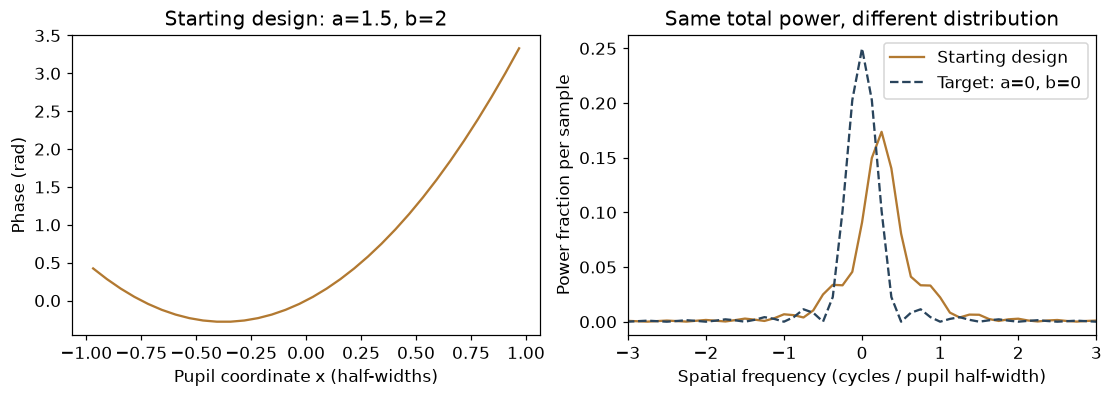

Initial dimensionless loss: 0.2605818922015634 | total power: 0.9999999999999998


In [2]:
def F(u):
    return np.fft.fftshift(np.fft.fft(np.fft.ifftshift(u), norm="ortho"))


def FH(v):
    return np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(v), norm="ortho"))


def pupil_grid(n=128):
    # Midpoints resolve a fixed aperture |x|<1 in a zero-padded width-8 window.
    if n < 16 or n % 8:
        raise ValueError("Use n divisible by eight, with n >= 16.")
    x = 8 * (np.arange(n) - (n - 1) / 2) / n
    amplitude = (abs(x) < 1).astype(float)
    amplitude /= np.linalg.norm(amplitude)
    frequency = (np.arange(n) - n // 2) / 8
    return x, amplitude, frequency


def forward(tilt=1.5, defocus=2., n=128, levels=None, piston=0.):
    x, amplitude, frequency = pupil_grid(n)
    phase = tilt * x + defocus * x**2 + piston
    if levels is not None:
        step = 2 * np.pi / levels
        phase = step * np.floor(phase / step + .5)
    pupil = amplitude * np.exp(1j * phase)
    field = F(pupil)
    return dict(x=x, amplitude=amplitude, frequency=frequency, phase=phase,
                pupil=pupil, field=field, intensity=abs(field)**2)


def evaluate(tilt=1.5, defocus=2., target=0., n=128):
    result = forward(tilt, defocus, n)
    target_intensity = forward(target, 0., n)["intensity"]
    scale = np.sum(target_intensity**2)
    residual = result["intensity"] - target_intensity
    loss = .5 * np.sum(residual**2) / scale
    back = FH(residual * result["field"] / scale)
    phase_gradient = 2 * np.imag(np.conj(result["pupil"]) * back)
    gradient = np.array([np.sum(phase_gradient * result["x"]),
                         np.sum(phase_gradient * result["x"]**2)])
    result.update(tilt=tilt, defocus=defocus, target=target, n=n,
                  target_intensity=target_intensity, loss=loss, gradient=gradient,
                  phase_gradient=phase_gradient, energy=np.sum(result["intensity"]))
    return result


start = evaluate()
assert abs(start["energy"] - 1) < 1e-13
assert evaluate(0., 0.)["loss"] == 0
# A global phase changes no measured intensity.
assert np.max(abs(forward(piston=.71)["intensity"] - start["intensity"])) < 1e-14
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
pupil = start["amplitude"] > 0
ax[0].plot(start["x"][pupil], start["phase"][pupil], color="#b27931")
ax[0].set(xlabel="Pupil coordinate x (half-widths)", ylabel="Phase (rad)",
          title="Starting design: a=1.5, b=2")
ax[1].plot(start["frequency"], start["intensity"], label="Starting design", color="#b27931")
ax[1].plot(start["frequency"], start["target_intensity"], "--", label="Target: a=0, b=0", color="#29445c")
ax[1].set(xlim=(-3, 3), xlabel="Spatial frequency (cycles / pupil half-width)",
          ylabel="Power fraction per sample", title="Same total power, different distribution")
ax[1].legend()
show(fig, "01-parameter-to-intensity")
print("Initial dimensionless loss:", start["loss"], "| total power:", start["energy"])

## 2 · Follow the chain rule backwards, then check it forwards

An intensity residual first creates the sensor sensitivity
q=(I−T)v/S. Propagate it through the adjoint operator: c=P†q.
The derivative for each real phase sample is gφ=2 Im(conj(u)c).
Because ∂φ/∂a=x and ∂φ/∂b=x², the two parameter derivatives are
∂L/∂a=Σgφ x and ∂L/∂b=Σgφ x². The sum is the chain rule, not a second simulation.

**Reverse-mode automatic differentiation** applies these derivative rules to a
computation graph automatically. Our explicit backward code exposes the same
calculation. An **adjoint method** supplies the backward sensitivity through an
optical operator or solver; it can be one operation within a larger graph.
Neither method replaces the choice of a correct forward model and useful loss.

We check the result in two independent ways. A forward tangent differentiates
the pupil first, dv/da=P(i x u), then evaluates
∂L/∂a=2 Re Σ[(I−T)conj(v)dv/da]/S. A central finite difference instead reruns
the full optical calculation at a±h. The latter costs two evaluations per variable.

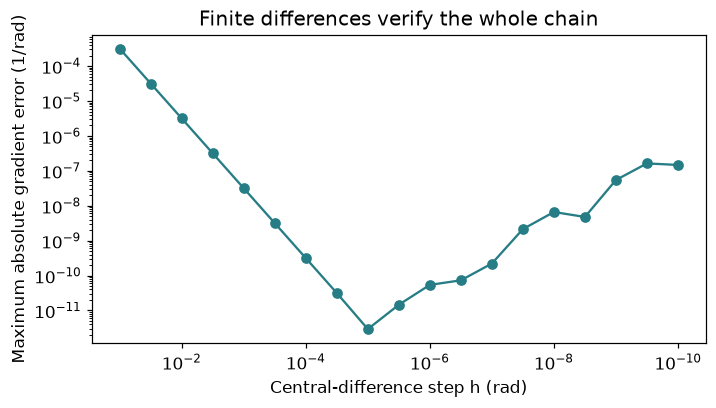

Reverse-mode gradient: [ 0.21889562 -0.041782  ]
Forward tangent gradient: [ 0.21889562 -0.041782  ]
Central-difference gradient: [ 0.21889562 -0.041782  ]
All power, piston, tangent, finite-difference, and grid-refinement checks passed.


In [3]:
def finite_difference(tilt=1.5, defocus=2., target=0., n=128, h=1e-5):
    parameters = np.array([tilt, defocus])
    gradient = []
    for direction in np.eye(2):
        plus = evaluate(*(parameters + h * direction), target=target, n=n)["loss"]
        minus = evaluate(*(parameters - h * direction), target=target, n=n)["loss"]
        gradient.append((plus - minus) / (2 * h))
    return np.array(gradient)


residual = start["intensity"] - start["target_intensity"]
scale = np.sum(start["target_intensity"]**2)
tangent_gradient = np.array([
    2 * np.real(np.sum(residual * np.conj(start["field"]) *
                       F(1j * start["x"]**power * start["pupil"]))) / scale
    for power in [1, 2]])
assert np.max(abs(tangent_gradient - start["gradient"])) < 1e-13
assert np.max(abs(finite_difference() - start["gradient"])) < 1e-9
assert abs(np.sum(start["phase_gradient"])) < 1e-13  # piston invariance
# Uniform-aperture centre power is independently M/N, here 1/4.
unaberrated = forward(0., 0.)
assert abs(unaberrated["intensity"][64] - .25) < 1e-14
# Refine the aperture quadrature without changing its width or image sampling.
finer = evaluate(n=256)
assert abs(finer["loss"] - start["loss"]) < 5e-4
assert np.max(abs(finer["gradient"] - start["gradient"])) < 5e-4
steps = np.logspace(-1, -10, 19)
errors = np.array([np.max(abs(finite_difference(h=h) - start["gradient"])) for h in steps])
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.loglog(steps, errors, "o-", color="#267d85")
ax.set(xlabel="Central-difference step h (rad)", ylabel="Maximum absolute gradient error (1/rad)",
       title="Finite differences verify the whole chain")
ax.invert_xaxis()
show(fig, "02-independent-gradient-check")
print("Reverse-mode gradient:", start["gradient"])
print("Forward tangent gradient:", tangent_gradient)
print("Central-difference gradient:", finite_difference())
print("All power, piston, tangent, finite-difference, and grid-refinement checks passed.")

## 3 · A correct gradient still needs a step size and an audit

We try θ_new=θ−η∇L, where θ=(a,b). A line search halves η until the *recomputed*
loss satisfies a decrease condition. Every row records the accepted parameters
and their loss, not the first proposed step. The target and normalization stay fixed.
At the default start, ∂L/∂b is negative: the first descent step increases defocus
while decreasing tilt. The two effects interact in the measured pattern, so the
gradient improves their combined loss rather than shrinking each coefficient.

**Predict:** will two initial designs necessarily converge to the same answer?
A second run from (3,3) tests this. The known zero-loss reference lets us identify
a poor stationary design even when its local gradient is small.

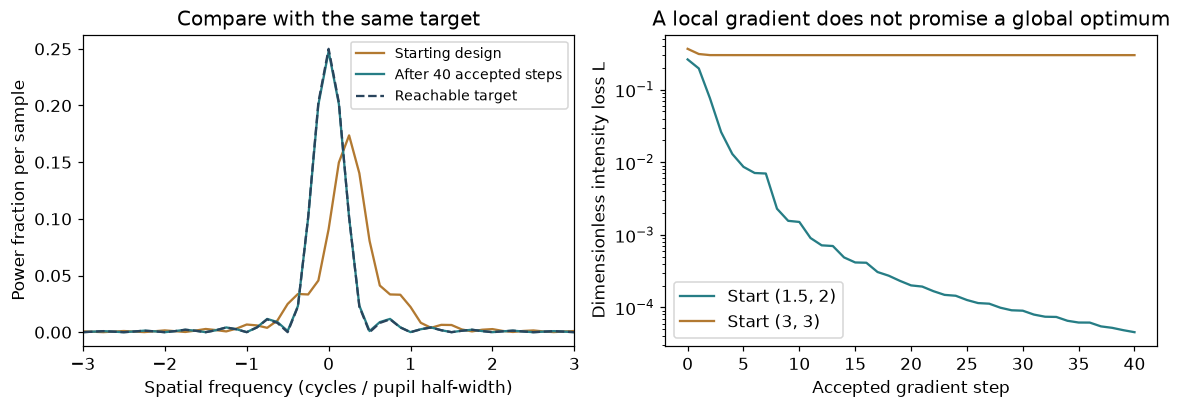

Default loss: 0.260581892 → 4.55734749e-05
Default final (tilt, defocus): 0.0025554446920561255 0.31416712799899355
Alternate-start final loss: 0.29866655495451416 | known reference loss: 0.0


In [4]:
def optimize(tilt=1.5, defocus=2., target=0., n=128, iterations=40, learning_rate=12.):
    best = evaluate(tilt, defocus, target, n)
    history = [dict(iteration=0, tilt=tilt, defocus=defocus, loss=best["loss"], step=0.)]
    for iteration in range(iterations):
        gradient = best["gradient"]
        norm2 = np.sum(gradient**2)
        if norm2 < 1e-22:
            break
        step = learning_rate
        for trial in range(24):
            candidate = evaluate(best["tilt"] - step * gradient[0],
                                 best["defocus"] - step * gradient[1], target, n)
            if candidate["loss"] <= best["loss"] - 1e-4 * step * norm2:
                best = candidate
                break
            step *= .5
        else:
            break
        history.append(dict(iteration=iteration+1, tilt=best["tilt"],
                            defocus=best["defocus"], loss=best["loss"], step=step))
    return best, history


best, history = optimize()
trapped, trapped_history = optimize(3., 3.)
losses = np.array([row["loss"] for row in history])
assert np.all(np.diff(losses) <= 1e-14)
assert best["loss"] < start["loss"] / 1000
assert trapped["loss"] > .1
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].plot(start["frequency"], start["intensity"], label="Starting design", color="#b27931")
ax[0].plot(best["frequency"], best["intensity"], label="After 40 accepted steps", color="#267d85")
ax[0].plot(best["frequency"], best["target_intensity"], "--", label="Reachable target", color="#29445c")
ax[0].set(xlim=(-3, 3), xlabel="Spatial frequency (cycles / pupil half-width)",
          ylabel="Power fraction per sample", title="Compare with the same target")
ax[0].legend(fontsize=9)
ax[1].semilogy([row["iteration"] for row in history], losses, label="Start (1.5, 2)", color="#267d85")
ax[1].semilogy([row["iteration"] for row in trapped_history], [row["loss"] for row in trapped_history],
               label="Start (3, 3)", color="#b27931")
ax[1].set(xlabel="Accepted gradient step", ylabel="Dimensionless intensity loss L",
          title="A local gradient does not promise a global optimum")
ax[1].legend()
show(fig, "03-optimization-and-local-minimum")
print("Default loss: %.9g → %.9g" % (start["loss"], best["loss"]))
print("Default final (tilt, defocus):", best["tilt"], best["defocus"])
print("Alternate-start final loss:", trapped["loss"], "| known reference loss:", evaluate(0., 0.)["loss"])

## Optional extension · Audit a quantized optic after optimizing a smooth one

A fabricated phase plate may allow only a few levels. Rounding its phase changes
the forward model. Away from a threshold, an infinitesimal parameter change leaves
all rounded phases unchanged, so its ordinary derivative is zero; at a jump the
derivative is undefined. The smooth-model gradient is not the derivative of this
discrete device. A small finite-difference step cannot repair that mismatch.

Use a shifted target (a_target=1) so a flat, single-level mask is not the answer.
Compare 2, 4, 8, and 16 levels using the same fixed target and power normalization.
This is an audit, not an optimizer for the quantized device. For an imaging system,
an end-to-end loss would also include the sensor and reconstruction or task model;
differentiating only this optical PSF does not by itself demonstrate end-to-end imaging.

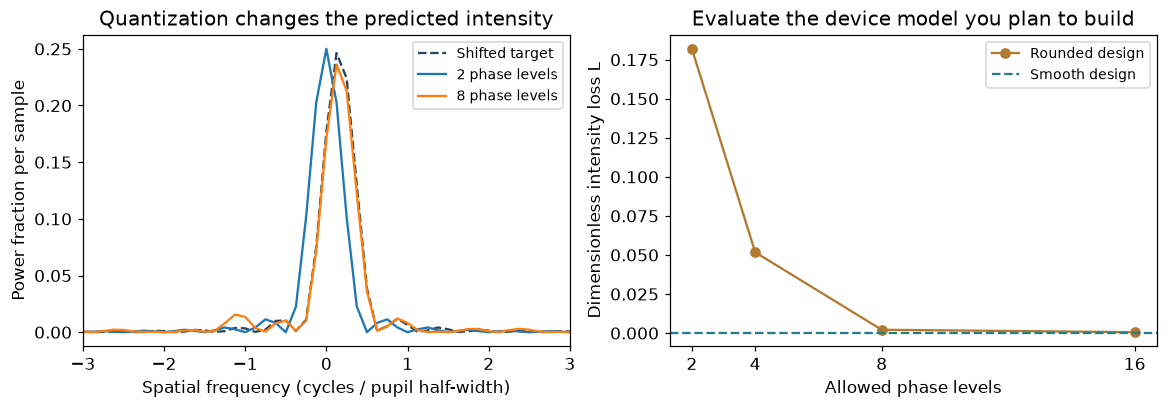

Shifted-target smooth loss: 1.0467096193108036e-05
Quantized losses: {2: np.float64(0.18188412075908036), 4: np.float64(0.05171459891535053), 8: np.float64(0.0021147036715357323), 16: np.float64(0.0005558446125280143)}
At the selected four-level design, the local finite-difference slope is zero.


In [5]:
shifted, _ = optimize(1.5, 2., target=1., iterations=80)
target = shifted["target_intensity"]
scale = np.sum(target**2)
levels = [2, 4, 8, 16]
quantized_losses = []
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].plot(shifted["frequency"], target, "--", color="#29445c", label="Shifted target")
for count in levels:
    quantized = forward(shifted["tilt"], shifted["defocus"], levels=count)
    loss = .5 * np.sum((quantized["intensity"] - target)**2) / scale
    quantized_losses.append(loss)
    assert abs(np.sum(quantized["intensity"]) - 1) < 1e-13
    if count in [2, 8]:
        ax[0].plot(quantized["frequency"], quantized["intensity"], label=str(count) + " phase levels")
ax[0].set(xlim=(-3, 3), xlabel="Spatial frequency (cycles / pupil half-width)",
          ylabel="Power fraction per sample", title="Quantization changes the predicted intensity")
ax[0].legend(fontsize=9)
ax[1].plot(levels, quantized_losses, "o-", color="#b27931", label="Rounded design")
ax[1].axhline(shifted["loss"], color="#267d85", linestyle="--", label="Smooth design")
ax[1].set(xlabel="Allowed phase levels", ylabel="Dimensionless intensity loss L",
          title="Evaluate the device model you plan to build", xticks=levels)
ax[1].legend(fontsize=9)
show(fig, "04-quantization-audit")
# The chosen point lies away from every rounding threshold for the finite pupil.
q0 = forward(.83, .71, levels=4)["intensity"]
qplus = forward(.83 + 1e-7, .71, levels=4)["intensity"]
qminus = forward(.83 - 1e-7, .71, levels=4)["intensity"]
assert np.array_equal(q0, qplus) and np.array_equal(q0, qminus)
print("Shifted-target smooth loss:", shifted["loss"])
print("Quantized losses:", dict(zip(levels, quantized_losses)))
print("At the selected four-level design, the local finite-difference slope is zero.")

## A short lab report

**1. Write the forward chain.** Name the design variables, fixed quantities, measurement and loss. Show why phase can change the focal intensity without changing pupil power.

**2. Audit both gradient components.** Compare reverse-mode and finite-difference derivatives over several perturbation sizes at the same initial design.

**3. Interpret the optimized result.** Report the initial and final loss, fixed target and power, and one limitation of the result.

### Worked reasoning

**Write the forward chain.** Unit-modulus phase preserves local pupil intensity; Fourier interference redistributes that fixed power among detector samples.

**Audit both gradient components.** Look for a range of h where truncation and roundoff errors are both small. Compare absolute errors when a true component is near zero.

**Interpret the optimized result.** A decreasing loss supports improvement for this sampled target. Intensity ambiguities, local stationary points and omitted physics prevent stronger conclusions.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [PyTorch · Autograd mechanics and complex-valued operations](https://docs.pytorch.org/docs/stable/notes/autograd.html)
- [Wang et al. · dO: A Differentiable Engine for Deep Lens Design](https://doi.org/10.1109/TCI.2022.3212837)
- [Sitzmann et al. · End-to-end optimization of optics and image processing](https://web.stanford.edu/~boyd/papers/pdf/end_to_end_opt_optics.pdf)
- [DeepLens · Differentiable optical models and examples](https://github.com/vccimaging/DeepLens)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e13_figures.zip


/tmp/optics-notebooks-w00ghsb7/E13/e13_figures.zip